# TF variability and positive TF regulators

chromVAR Z-scores tell you *which* motifs are accessible in *which* cells. Two
follow-up questions from the ArchR workflow are covered here:

1. **Which motifs vary the most across cells?** — `epi.tl.var_deviations`
   (port of ArchR `getVarDeviations`) and `epi.pl.var_dev` (`plotVarDev`).
2. **Which TFs are *positive regulators*, i.e. their motif accessibility rises
   together with the TF's own gene activity?** — `epi.tl.correlate_matrices`
   (port of ArchR `correlateMatrices`) and `epi.tl.positive_tf_regulators`
   (the "Identification of Positive TF-Regulators" recipe of the ArchR book).

Every number in this notebook is checked against ArchR 1.0.3 run on the same
data in the last section.

## How the methods work

**Variability.** For every motif ArchR keeps, per sample, the mean and the
unbiased variance of its Z-scores and pools them
(`combinedVars = (Σ (n_s−1)·var_s + n_s·mean_s² − N·mean²) / (N−1)`), which is the
variance over all cells. Motifs are ranked by this value.

**correlateMatrices.** Single cells are too sparse to correlate gene scores with
motif Z-scores directly, so ArchR

1. draws `knn_iteration = 500` seed cells (`set.seed(1); sample()`),
2. takes each seed's `k = 100` nearest neighbours in the (row-z-scored)
   IterativeLSI space,
3. drops groups that share more than `overlap_cutoff·k = 80` cells with an earlier kept group,
4. averages each matrix over the groups, applies `log2(x+1)` to non-negative
   matrices (gene scores; Z-scores are left as is),
5. pairs features by upper-cased name (`GATA1` ↔ `GATA1_383`) and runs a Pearson
   `cor.test` per pair with Bonferroni correction.

Epione reproduces R's random stream bit-exactly — by default the
`L'Ecuyer-CMRG` generator that `addArchRThreads()` switches a multi-threaded
ArchR session to (`rng="archr"`; `rng="R"` for R's default Mersenne-Twister) —
so the seed cells and therefore the groups are *identical* to ArchR's.

**Positive TF regulators.** `maxDelta` = largest difference of cluster-mean
Z-scores between any two clusters. A TF is a positive regulator when
`cor > 0.5`, `padj < 0.01` and `maxDelta` is above its 75th percentile.

## Setup — ArchR hematopoiesis data

We use the ArchR tutorial data (BMMC, CD34⁺ BMMC and PBMC; 10,660 cells).
The inputs below are the IterativeLSI, gene-score matrix and cisbp chromVAR
Z-scores of that project, exported by `tests/parity/var_dev_correlate/r_reference.R`.
With Epione alone the same inputs come from `epi.tl.iterative_lsi`,
`epi.tl.add_gene_score_matrix` and `epi.tl.compute_deviations` (see the
chromVAR tutorial).

In [1]:
import os, json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
from scipy import io, stats
import matplotlib.pyplot as plt
from IPython.display import display, Image
import epione as epi

DATA = Path(os.environ.get('EPIONE_VDC_DATA',
    '/scratch/users/steorra/analysis/25_epione/epione_dev/work/var-dev-correlate/ref'))
FIX = Path('/scratch/users/steorra/analysis/25_epione/epione_dev/fixture/tables')
print(epi.__file__)

/scratch/users/steorra/analysis/25_epione/epione_dev/wt/var-dev-correlate/epione/__init__.py


In [2]:
%%time
cells = pd.read_csv(DATA / 'cells.tsv', sep='\t').set_index('barcode')
gs = io.mmread(DATA / 'genescore.mtx').tocsr().T.tocsr()                 # cells × genes
genes = pd.read_csv(DATA / 'genescore_features.tsv', sep='\t')
lsi = pd.read_csv(DATA / 'lsi_raw.tsv', sep='\t').set_index('barcode').loc[cells.index]
z = pd.read_csv(DATA / 'cisbp_z.tsv.gz', sep='\t').set_index('motif')[cells.index]

adata = ad.AnnData(X=gs, obs=cells)
adata.var_names = genes['name'].astype(str).to_numpy()
adata.obsm['X_iterative_lsi'] = lsi.to_numpy()          # raw ArchR IterativeLSI (30 dims)
adata.obsm['motif_deviations'] = z.to_numpy().T          # chromVAR Z, cells × motifs
adata.uns['motif_deviations_names'] = z.index.to_numpy()
adata

CPU times: user 5.04 s, sys: 863 ms, total: 5.9 s
Wall time: 4.13 s


AnnData object with n_obs × n_vars = 10660 × 23127
    obs: 'Sample', 'Clusters'
    uns: 'motif_deviations_names'
    obsm: 'X_iterative_lsi', 'motif_deviations'

## 1 · Motif variability (`getVarDeviations`)

In [3]:
var = epi.tl.var_deviations(adata, key='motif_deviations', sample_key='Sample')
var.head(10)

   var_deviations: top = SPIB_336, CEBPA_155, GATA2_388, GATA1_383, CEBPB_140


,seqnames,idx,name,combinedVars,combinedMeans,rank
0,z,336,SPIB_336,13.531172,-0.082976,1
1,z,155,CEBPA_155,11.810713,-0.175367,2
2,z,388,GATA2_388,10.677346,-0.025474,3
3,z,383,GATA1_383,10.398065,-0.035745,4
4,z,140,CEBPB_140,10.381894,-0.131971,5
5,z,139,JUNB_139,9.692036,-0.162710,6
6,z,142,FOSL1_142,9.624370,-0.151152,7
7,z,651,SMARCC1_651,9.554103,-0.144721,8
8,z,124,JUND_124,9.522628,-0.149847,9
9,z,105,FOSL2_105,9.516122,-0.152608,10


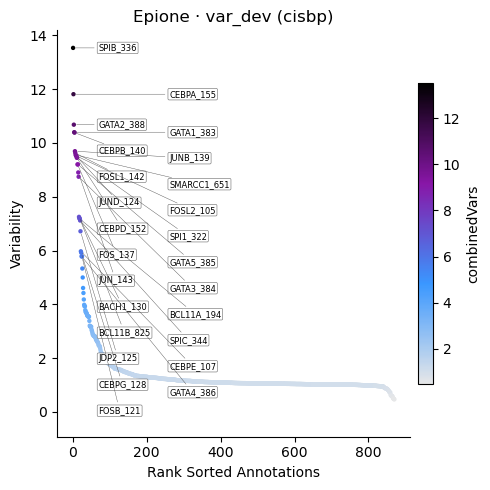

In [4]:
fig, ax = epi.pl.var_dev(adata, n=25, show=False)
ax.set_title('Epione · var_dev (cisbp)')
plt.tight_layout(); plt.show()

The most variable motifs are lineage TFs of hematopoiesis — SPIB/SPI1 and
CEBPA/CEBPB (myeloid/DC), GATA1/GATA2 (erythroid–megakaryocyte) — followed by
the AP-1 (JUN/FOS) family, the same ranking ArchR reports (parity section).

## 2 · Correlating gene scores with motif Z-scores (`correlateMatrices`)

In [5]:
%%time
cor = epi.tl.correlate_matrices(
    adata, key2='motif_deviations',
    name1='GeneScoreMatrix', name2='MotifMatrix',
    use_rep='X_iterative_lsi', scale_dims=True,      # ArchR IterativeLSI default scaleDims=TRUE
    dims_to_use=range(1, 31),
    k=100, knn_iteration=500, overlap_cutoff=0.8, seed=1,
    cor_cutoff=None,                                 # no LSI dim of this project exceeds |r|=0.75
)
print(len(cor.attrs['groups']), 'kNN groups')
cor.sort_values('cor', ascending=False).head(10)

   correlate_matrices: testing 825 mappings
   correlate_matrices: 492 non-overlapping kNN groups


492 kNN groups
CPU times: user 851 ms, sys: 413 ms, total: 1.26 s
Wall time: 1.21 s


,GeneScoreMatrix_name,MotifMatrix_name,cor,padj,pval,GeneScoreMatrix_matchName,MotifMatrix_matchName,GeneScoreMatrix_idx,MotifMatrix_idx
586,LEF1,LEF1_760,0.920358,5.177784e-199,6.329809e-202,LEF1,LEF1,16831,760
587,LEF1-AS1,LEF1_760,0.898741,1.177104e-174,1.439002e-177,LEF1,LEF1,16832,760
805,GATA1,GATA1_383,0.872442,1.467879e-151,1.794473e-154,GATA1,GATA1,22455,383
175,NFE2,NFE2_119,0.868278,2.236648e-148,2.734289e-151,NFE2,NFE2,5181,119
245,JDP2,JDP2_125,0.838194,3.349865e-128,4.095190e-131,JDP2,JDP2,6721,125
550,MITF,MITF_91,0.824729,1.800763e-120,2.201422e-123,MITF,MITF,15542,91
611,TCF7,TCF7_750,0.823206,1.223336e-119,1.495521e-122,TCF7,TCF7,17690,750
210,FOXO1,FOXO1_361,0.816979,2.570801e-116,3.142789e-119,FOXO1,FOXO1,5958,361
386,CEBPA-DT,CEBPA_155,0.814493,5.029399e-115,6.148409e-118,CEBPA,CEBPA,11139,155
501,CEBPB,CEBPB_140,0.813203,2.309855e-114,2.823784e-117,CEBPB,CEBPB,14004,140


`cor_cutoff` filtering needs per-dimension correlation to sequencing depth; on
this project ArchR's `getReducedDims(corCutOff = 0.75)` keeps all 30 dimensions
after row scaling (checked in the parity section), so it is disabled here.

## 3 · Positive TF regulators

In [6]:
%%time
tf = epi.tl.positive_tf_regulators(
    adata, motif_key='motif_deviations', groupby='Clusters',
    use_rep='X_iterative_lsi', scale_dims=True, dims_to_use=range(1, 31), cor_cutoff=None,
    k=100, knn_iteration=500, seed=1,
)
tf[tf.TFRegulator == 'YES'][['GeneScoreMatrix_name', 'MotifMatrix_name', 'cor', 'padj', 'maxDelta']]

   correlate_matrices: testing 825 mappings
   correlate_matrices: 492 non-overlapping kNN groups


   positive_tf_regulators: 39 positive regulators: LEF1, GATA1, NFE2, JDP2, MITF, TCF7, CEBPA-DT, CEBPB, CEBPD, NFIL3, EBF1, BCL11A, EOMES, FUBP1, MEF2A, NFIX, SPI1, GATA5, ZEB1-AS1, SMAD1
CPU times: user 953 ms, sys: 266 ms, total: 1.22 s
Wall time: 1.08 s


,GeneScoreMatrix_name,MotifMatrix_name,cor,padj,maxDelta
0,LEF1,LEF1_760,0.920358,5.177784e-199,2.096619
1,GATA1,GATA1_383,0.872442,1.467879e-151,10.103413
2,NFE2,NFE2_119,0.868278,2.236648e-148,4.184249
3,JDP2,JDP2_125,0.838194,3.349865e-128,5.336864
5,MITF,MITF_91,0.824729,1.800763e-120,1.745067
6,TCF7,TCF7_750,0.823206,1.223336e-119,1.658758
8,CEBPA-DT,CEBPA_155,0.814493,5.029399e-115,7.549040
9,CEBPB,CEBPB_140,0.813203,2.309855e-114,6.917439
12,CEBPD,CEBPD_152,0.788874,9.263506e-103,6.805476
13,NFIL3,NFIL3_133,0.782378,6.417371e-100,1.803920


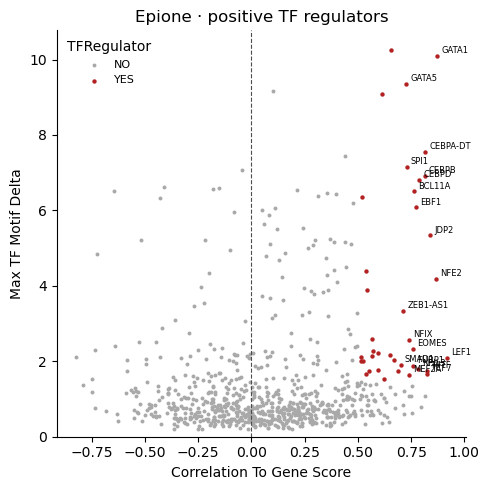

In [7]:
fig, ax = epi.pl.tf_regulators(adata, show=False)
ax.set_title('Epione · positive TF regulators')
plt.tight_layout(); plt.show()

## 4 · Parity vs ArchR 1.0.3

The R driver `tests/parity/var_dev_correlate/r_reference.R` runs
`getVarDeviations`, `correlateMatrices(GeneScoreMatrix, cisbpMatrix)`,
`getGroupSE` and the ArchR-book TF-regulator recipe on the same project;
`py_parity.py` runs Epione and compares against the gates pre-registered in
`MANIFEST.md` (omicverse-rebuildr parity taxonomy).

In [8]:
%%time
sys.path.insert(0, str(Path(epi.__file__).parents[1] / 'tests' / 'parity' / 'var_dev_correlate'))
from py_parity import run
m = run(DATA)
gates = [
    ('getVarDeviations combinedVars (JASPAR MotifMatrix)', '1', 'max abs err', 1e-8, m['vardev_MotifMatrix_combinedVars_maxabs']),
    ('getVarDeviations combinedMeans (JASPAR MotifMatrix)', '1', 'max abs err', 1e-8, m['vardev_MotifMatrix_combinedMeans_maxabs']),
    ('getVarDeviations rank (JASPAR)', '1', 'mismatches', 0, m['vardev_MotifMatrix_rank_mismatches']),
    ('getVarDeviations combinedVars (cisbp)', '1', 'max abs err', 1e-8, m['vardev_cisbpMatrix_combinedVars_maxabs']),
    ('getVarDeviations rank (cisbp)', '1', 'mismatches', 0, m['vardev_cisbpMatrix_rank_mismatches']),
    ('getReducedDims (scaleDims) input', '1', 'max abs err', 1e-8, m['reducedDims_maxabs']),
    ("seed cells: set.seed(1); sample() (L'Ecuyer-CMRG)", '1', 'mismatches', 0, m['seed_cells_archr_rng_mismatches']),
    ('kNN groups after overlap filter', '1', 'set mismatches', 0, m['knn_group_set_mismatches']),
    ('correlateMatrices cor', '1', 'max abs err', 1e-8, m['cor_maxabs']),
    ('correlateMatrices -log10 pval', '1 (bounded)', 'max abs err', 1e-6, m['nlog10_pval_maxabs']),
    ('correlateMatrices -log10 padj', '1 (bounded)', 'max abs err', 1e-6, m['nlog10_padj_maxabs']),
    ('getGroupSE cluster means', '1', 'max abs err', 1e-8, m['groupSE_maxabs']),
    ('maxDelta', '1', 'max abs err', 1e-8, m['maxDelta_maxabs']),
    ('correlateMatrices end-to-end (rng="archr") cor', '1', 'max abs err', 1e-8, m['archr_rng_cor_maxabs']),
    ('positive TF regulators (rng="archr")', '7', 'identical set', True, m['tf_yes_identical_archr_rng']),
    ('positive TF regulator table order', '7', 'identical', True, m['tf_table_order_identical_archr_rng']),
    ('free-running (numpy RNG) cor', '8', 'Spearman', 0.90, m['free_numpy_spearman_cor']),
    ('free-running (numpy RNG) -log10 padj', '8', 'Spearman', 0.90, m['free_numpy_spearman_nlog10_padj']),
    ('free-running (numpy RNG) regulator set', '5', 'Jaccard', 0.80, m['free_numpy_tf_jaccard']),
]
def passed(thr, v):
    if isinstance(thr, bool): return v == thr
    if thr in (0,) and isinstance(v, (int, np.integer)): return v == 0
    return v <= thr if thr < 0.5 else v >= thr
tab = pd.DataFrame(gates, columns=['output', 'class', 'metric', 'threshold', 'value'])
tab['pass'] = [passed(t, v) for t, v in zip(tab.threshold, tab.value)]
fmt = lambda v: v if isinstance(v, (bool, np.bool_, int, np.integer)) else (f'{v:.2e}' if abs(v) < 0.01 else f'{v:.4f}')
tab['threshold'] = tab.threshold.map(fmt); tab['value'] = tab.value.map(fmt)
pd.set_option('display.max_colwidth', 60)
display(tab)
print('ArchR YES :', m['tf_yes_r'])
print('Epione YES:', m['tf_yes_py_archr_rng'])
assert tab['pass'].all()

,output,class,metric,threshold,value,pass
0,getVarDeviations combinedVars (JASPAR MotifMatrix),1,max abs err,1.00e-08,2.84e-14,True
1,getVarDeviations combinedMeans (JASPAR MotifMatrix),1,max abs err,1.00e-08,6.38e-16,True
2,getVarDeviations rank (JASPAR),1,mismatches,0,0,True
3,getVarDeviations combinedVars (cisbp),1,max abs err,1.00e-08,4.26e-14,True
4,getVarDeviations rank (cisbp),1,mismatches,0,0,True
5,getReducedDims (scaleDims) input,1,max abs err,1.00e-08,1.38e-14,True
6,seed cells: set.seed(1); sample() (L'Ecuyer-CMRG),1,mismatches,0,0,True
7,kNN groups after overlap filter,1,set mismatches,0,0,True
8,correlateMatrices cor,1,max abs err,1.00e-08,8.33e-16,True
9,correlateMatrices -log10 pval,1 (bounded),max abs err,1.00e-06,3.77e-13,True


ArchR YES : ['ASCL1', 'BCL11A', 'CEBPA-DT', 'CEBPB', 'CEBPD', 'EBF1', 'EGR2', 'EOMES', 'ERF', 'ETS1', 'ETV6', 'FUBP1', 'GATA1', 'GATA2', 'GATA5', 'IRF7', 'JDP2', 'LEF1', 'MECOM', 'MEF2A', 'MITF', 'NFE2', 'NFIA', 'NFIB', 'NFIC', 'NFIL3', 'NFIX', 'NFKB2', 'PAX5', 'POU2F1', 'REL', 'SMAD1', 'SPI1', 'SPIB', 'TAL1', 'TCF15', 'TCF7', 'TFAP2C', 'ZEB1-AS1']
Epione YES: ['ASCL1', 'BCL11A', 'CEBPA-DT', 'CEBPB', 'CEBPD', 'EBF1', 'EGR2', 'EOMES', 'ERF', 'ETS1', 'ETV6', 'FUBP1', 'GATA1', 'GATA2', 'GATA5', 'IRF7', 'JDP2', 'LEF1', 'MECOM', 'MEF2A', 'MITF', 'NFE2', 'NFIA', 'NFIB', 'NFIC', 'NFIL3', 'NFIX', 'NFKB2', 'PAX5', 'POU2F1', 'REL', 'SMAD1', 'SPI1', 'SPIB', 'TAL1', 'TCF15', 'TCF7', 'TFAP2C', 'ZEB1-AS1']
CPU times: user 11.6 s, sys: 2.06 s, total: 13.6 s
Wall time: 11.5 s


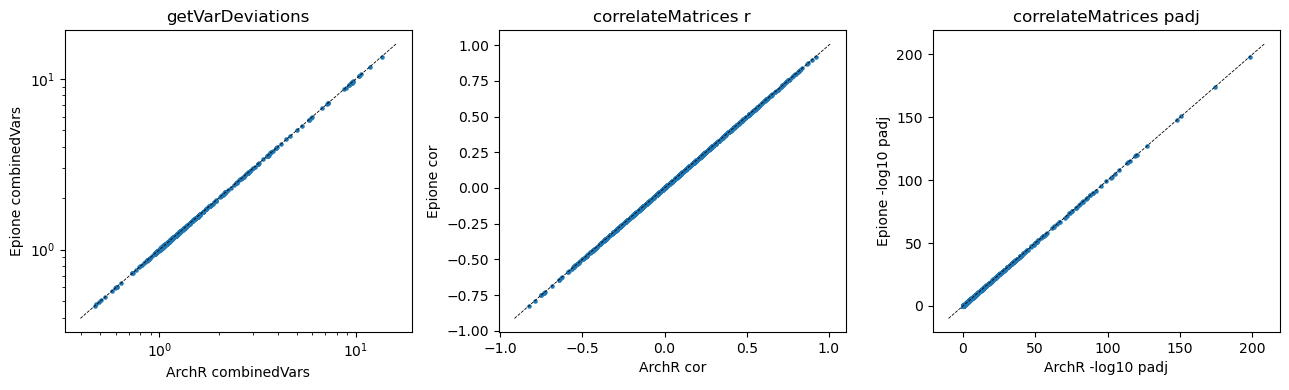

In [9]:
r = pd.read_csv(DATA / 'correlateMatrices_GSM_cisbp.tsv', sep='\t')
py = epi.tl.correlate_matrices(adata, key2='motif_deviations', name1='GeneScoreMatrix', name2='cisbpMatrix',
                               use_rep='X_iterative_lsi', scale_dims=True, dims_to_use=range(1, 31),
                               cor_cutoff=None, verbose=False)
mm = r.merge(py, on=['GeneScoreMatrix_name', 'cisbpMatrix_name'], suffixes=('_ArchR', '_Epione'))
rv = pd.read_csv(DATA / 'vardev_cisbpMatrix.tsv', sep='\t').merge(var, on='name', suffixes=('_ArchR', '_Epione'))
nl = lambda p: -np.log10(np.clip(p, 1e-300, None))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].scatter(rv.combinedVars_ArchR, rv.combinedVars_Epione, s=5)
axes[0].set(xlabel='ArchR combinedVars', ylabel='Epione combinedVars', title='getVarDeviations', xscale='log', yscale='log')
axes[1].scatter(mm.cor_ArchR, mm.cor_Epione, s=5)
axes[1].set(xlabel='ArchR cor', ylabel='Epione cor', title='correlateMatrices r')
axes[2].scatter(nl(mm.padj_ArchR), nl(mm.padj_Epione), s=5)
axes[2].set(xlabel='ArchR -log10 padj', ylabel='Epione -log10 padj', title='correlateMatrices padj')
for ax in axes:
    lo, hi = ax.get_xlim(); ax.plot([lo, hi], [lo, hi], 'k--', lw=0.6)
plt.tight_layout(); plt.show()

ArchR's own figures for the same data (rendered by `r_reference.R`):

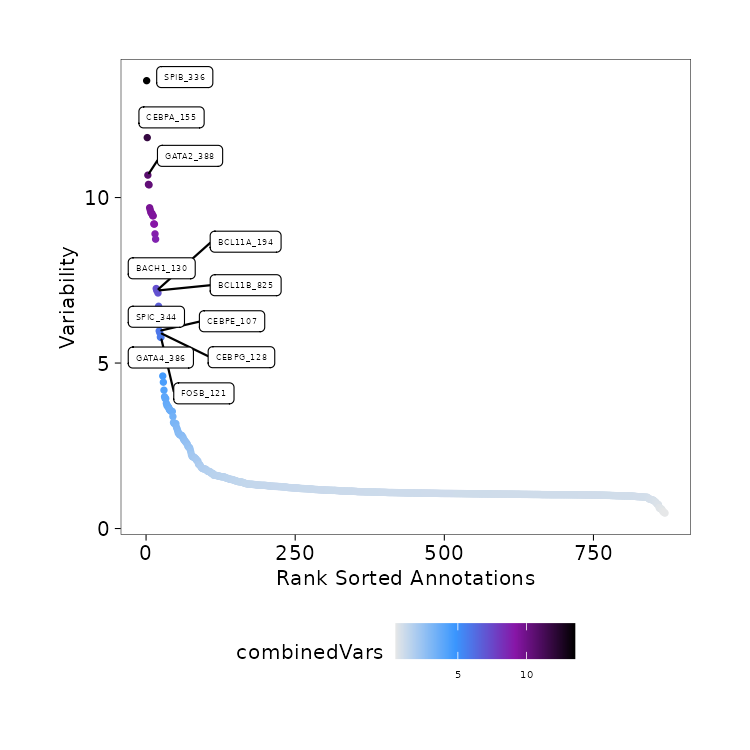

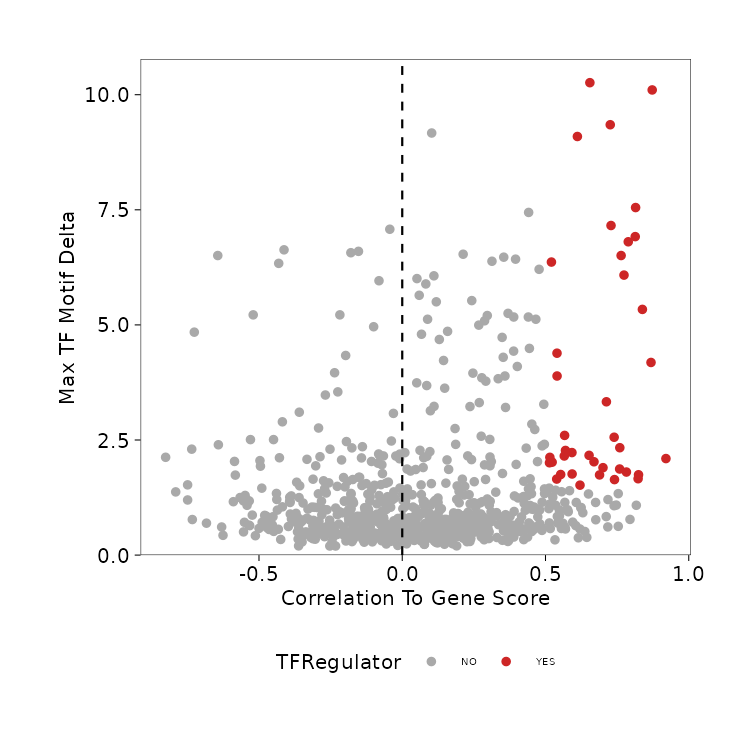

In [10]:
display(Image(str(DATA / 'plotVarDev_cisbp.png'), width=380))
display(Image(str(DATA / 'positive_tf_regulators.png'), width=380))

### Notes
* `rng="archr"` (default) emulates `set.seed()` / `sample()` of a
  multi-threaded ArchR session bit-exactly, so Epione and ArchR test the
  *same* kNN groups. `rng="numpy"` gives a different
  but equally valid set of groups; the correlations then agree at the
  statistical level (Spearman ≥ 0.9) rather than to machine precision.
* The kNN search is exact Euclidean (ArchR uses `nabor::knn`), ties broken by
  cell index.
* Correlations need matching names: cisbp motif names (`GATA1_383`) map to
  genes after stripping `_…`/`-…`; JASPAR matrix IDs (`MA0035.4`) carry no
  gene symbol and need to be renamed to TF names first.